In [7]:
# From arb
from pynq import Overlay
import xrfclk
from pynq import PL
import pynq
from pynq.lib import AxiGPIO

# From ADC part
from adc_scope import AdcScope

import xrfdc
import matplotlib.pyplot as plt
%matplotlib inline

# From AWG part
import numpy as np
from rfsoc_awg import *      # AWG, Pulse and the unit helpers ns, us, kHz, MHz, GHz

In [8]:
PL.reset()
xrfclk.set_ref_clks(lmk_freq=245.76, lmx_freq=491.52)   #Programs the oscillators on the board to produce the appropriate clock signals

ol = Overlay("awg_adc.bit") #Load the FPGA bit file 

In [9]:
## DAC

# Length of ONE waveform slot. It is rounded to a multiple of 1.6276 ns; the real value is printed.
# (Max 26.67 us.)
awg = AWG(window=10 * us, bitfile=ol)

awg.connect()    # load bitstream, program clocks, reset the AWG logic
# awg.upload()     # send waveforms + length to the board RAM
# awg.start()      # enable the outputs

# Bug that we need it?
# awg.play()       # = stop -> upload -> start

Window = 10.0000 us  (98304 samples, 6144 clock cycles)  [requested 10.0000 us]


In [10]:
sc = AdcScope(ol)
sc.configure(trigger="awg2", pre_ns=10, length_ns=1000)

Window = 26.6667 us  (262144 samples, 16384 clock cycles)  [requested 26.6667 us]
Window set to 26.67 us so that low frequencies fit (max possible is 26.67 us)
NOTE: the AWG window (26.67 us) cannot hold fewer than 1 cycle, so the lowest usable frequency is 37.5 kHz (not 1 kHz). Starting there.
Bode sweep 3.75e+04 .. 1.012e+06 Hz, 27 points, amp 100 mV, window 26.67 us (frequency grid 3.75e+04 Hz), trigger=awg2
DMA upload took 0.0066 s
Playing slot x on ['DAC_A']
  [  1/27]        37500 Hz   ADC amplitude 0.0000 FS
DMA upload took 0.0066 s
DMA upload took 0.0066 s
DMA upload took 0.0066 s
DMA upload took 0.0087 s
DMA upload took 0.0065 s
DMA upload took 0.0066 s
DMA upload took 0.0068 s
DMA upload took 0.0066 s
DMA upload took 0.0066 s
DMA upload took 0.0066 s
  [ 11/27]    4.125e+05 Hz   ADC amplitude 0.0788 FS
DMA upload took 0.0066 s
DMA upload took 0.0066 s
DMA upload took 0.0066 s
DMA upload took 0.0066 s
DMA upload took 0.0066 s
DMA upload took 0.0066 s
DMA upload took 0.0066 s
D

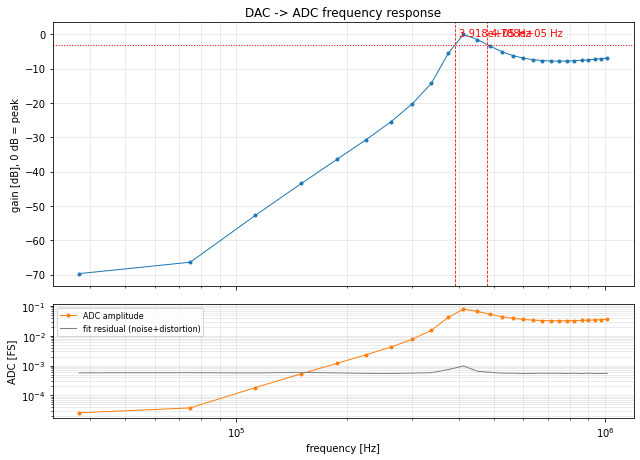

(391845.5669927215, 478770.9895749448)

In [11]:
from bode_sweep import run_bode
res = run_bode(awg, sc, fmin=1e3, fmax=1e6, points=100, amp=0.1, dac="DAC_A", slot="x", out="fmin=1e3, fmax=1e6,points=100")
res["bw_low_hz"], res["bw_high_hz"]       # -3 dB band edges

Window = 26.6667 us  (262144 samples, 16384 clock cycles)  [requested 26.6667 us]
Window set to 26.67 us so that low frequencies fit (max possible is 26.67 us)
NOTE: the AWG window (26.67 us) cannot hold fewer than 1 cycle, so the lowest usable frequency is 37.5 kHz (not 1 kHz). Starting there.
Bode sweep 3.75e+04 .. 6.25e+08 Hz, 626 points, amp 100 mV, window 26.67 us (frequency grid 3.75e+04 Hz), trigger=awg2
DMA upload took 0.0066 s
Playing slot x on ['DAC_A']
  [  1/626]        37500 Hz   ADC amplitude 0.0000 FS
DMA upload took 0.0066 s
DMA upload took 0.0065 s
DMA upload took 0.0066 s
DMA upload took 0.0077 s
DMA upload took 0.0066 s
DMA upload took 0.0066 s
DMA upload took 0.0066 s
DMA upload took 0.0066 s
DMA upload took 0.0066 s
DMA upload took 0.0066 s
  [ 11/626]    4.125e+05 Hz   ADC amplitude 0.0792 FS
DMA upload took 0.0066 s
DMA upload took 0.0066 s
DMA upload took 0.0066 s
DMA upload took 0.0066 s
DMA upload took 0.0066 s
DMA upload took 0.0065 s
DMA upload took 0.0065 s

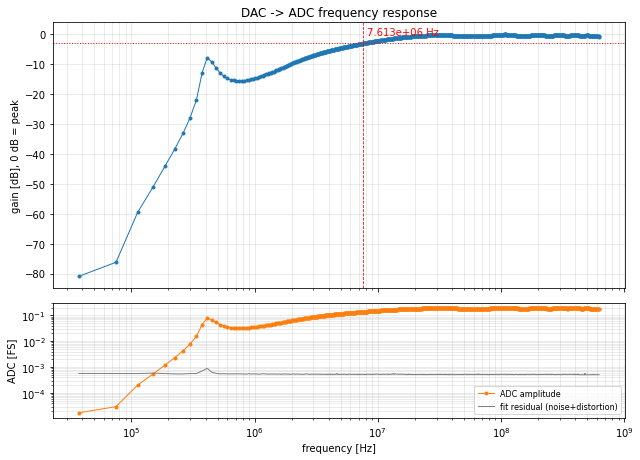

(7612612.135465877, None)

In [6]:
from bode_sweep import run_bode
res = run_bode(awg, sc, fmin=1e3, fmax=625e6, points=1000, amp=0.1, dac="DAC_A", slot="x", out="fmin=1e3, fmax=1e9, points=1000")
res["bw_low_hz"], res["bw_high_hz"]       # -3 dB band edges

In [14]:
from bode_sweep import run_bode
res = run_bode(awg, sc, fmin=1e3, fmax=625e6, points=1000, amp=0.1, dac="DAC_B", slot="x", out="ignore")
res["bw_low_hz"], res["bw_high_hz"]       # -3 dB band edges

Window = 26.6667 us  (262144 samples, 16384 clock cycles)  [requested 26.6667 us]
Window set to 26.67 us so that low frequencies fit (max possible is 26.67 us)
NOTE: the AWG window (26.67 us) cannot hold fewer than 1 cycle, so the lowest usable frequency is 37.5 kHz (not 1 kHz). Starting there.
Bode sweep 3.75e+04 .. 6.25e+08 Hz, 626 points, amp 100 mV, window 26.67 us (frequency grid 3.75e+04 Hz), trigger=awg0
DMA upload took 0.0066 s
Playing slot x on ['DAC_B']
  [  1/626]        37500 Hz   ADC amplitude 0.0000 FS
DMA upload took 0.0065 s
DMA upload took 0.0066 s
DMA upload took 0.0067 s
DMA upload took 0.0083 s
DMA upload took 0.0067 s
DMA upload took 0.0065 s
DMA upload took 0.0065 s
DMA upload took 0.0065 s
DMA upload took 0.0066 s
DMA upload took 0.0065 s
  [ 11/626]    4.125e+05 Hz   ADC amplitude 0.0000 FS
DMA upload took 0.0066 s
DMA upload took 0.0065 s
DMA upload took 0.0066 s
DMA upload took 0.0065 s
DMA upload took 0.0065 s
DMA upload took 0.0066 s
DMA upload took 0.0066 s

KeyboardInterrupt: 